# Gradients of the Softmax Network (Optional)

Open in [Google Colab](https://colab.research.google.com/github/febse/ta2025/blob/main/03-08-ANN-Multiclass-Derivatives-Optional.ipynb)

This chapter is **optional**. It derives, step by step, the gradients of a softmax network with a hidden layer that are used for training in the [previous chapter](03-07-ANN-Multiclass-Classification.ipynb). The results are summarized in that chapter, so you can skip the derivation and still follow the rest of the course. If you want to know where the formulas come from, or to see them checked against PyTorch's automatic differentiation, read on.

## The Network and the Loss

We consider a network with one hidden layer with $k$ neurons and a non-linear activation function $\varphi$ (ReLU, tanh, ...) and derive the gradients that gradient descent needs. The derivation follows the ones for the regression network and the binary classification network in the previous chapters; only the output layer and the loss change.

### The model in matrix notation

Let $n$ be the number of observations, $p$ the number of features, $k$ the number of hidden neurons and $K$ the number of classes. We use the same row-vector convention as before (observations are rows, every layer multiplies from the right):

| Symbol | Meaning | Shape |
|---|---|---|
| $X$ | data matrix | $n \times p$ |
| $Y$ | one-hot encoded labels | $n \times K$ |
| $W_h$, $b_h$ | hidden layer weights, bias (row vector) | $p \times k$, $1 \times k$ |
| $W_o$, $b_o$ | output layer weights, bias (row vector) | $k \times K$, $1 \times K$ |
| $H$ | hidden net values (pre-activations) | $n \times k$ |
| $Z$ | hidden activations | $n \times k$ |
| $O$ | output net values (logits) | $n \times K$ |
| $\hat{Y}$ | predicted probabilities | $n \times K$ |

$$
\begin{align*}
H & = X W_h + b_h \\
Z & = \varphi(H) \\
O & = Z W_o + b_o \\
\hat{Y} & = \text{softmax}(O) \\
L & = -\frac{1}{n} \sum_{i=1}^n \sum_{j=1}^K y_{ij} \log \hat{y}_{ij}
\end{align*}
$$

The activation $\varphi$ is applied element-wise, the softmax is applied to each row of $O$, and the bias row vectors $b_h$, $b_o$ are added to every row (broadcasting). Formally this is $\mathbf{1} b_h$ and $\mathbf{1} b_o$ with $\mathbf{1}$ a vector of $n$ ones. Note that $Z$ here are the *activations* of the hidden layer, not logits; the logits are $O$.

The derivation has three steps: (1) the derivative of the softmax, (2) the derivative of the loss with respect to the logits $O$, and (3) back-propagation of this derivative through the output layer and the hidden layer with the chain rule.

### Step 1: Derivative of the softmax

**Statement.** Let $o = (o_1, \ldots, o_K)$ be the logits of one observation and $\hat{y}_j = e^{o_j} / \sum_{m} e^{o_m}$. Then for all $j, m \in \{1, \ldots, K\}$

$$
\frac{\partial \hat{y}_j}{\partial o_m} = \hat{y}_j (\delta_{jm} - \hat{y}_m)
$$

where $\delta_{jm}$ is 1 if $j = m$ and 0 otherwise. In matrix form the $K \times K$ Jacobian is $\text{diag}(\hat{y}) - \hat{y}^\top \hat{y}$ (a symmetric matrix, $\hat{y}$ being a row vector).

**Proof.** Write $s = \sum_{m} e^{o_m}$, so that $\hat{y}_j = e^{o_j}/s$ and $\partial s / \partial o_m = e^{o_m}$. By the quotient rule

$$
\frac{\partial \hat{y}_j}{\partial o_m}
= \frac{\delta_{jm} e^{o_j} \, s - e^{o_j} e^{o_m}}{s^2}
= \delta_{jm} \frac{e^{o_j}}{s} - \frac{e^{o_j}}{s}\frac{e^{o_m}}{s}
= \delta_{jm} \hat{y}_j - \hat{y}_j \hat{y}_m. \qquad \blacksquare
$$

In particular, $\partial \hat{y}_j / \partial o_j = \hat{y}_j(1 - \hat{y}_j)$ (the derivative of the sigmoid is the special case $K = 2$) and $\partial \hat{y}_j / \partial o_m = -\hat{y}_j \hat{y}_m$ for $j \neq m$: increasing one logit raises its own probability and lowers all the others.

### Step 2: Derivative of the cross-entropy loss with respect to the logits

**Statement.** For one observation $i$ with one-hot label $y_i$ and loss $L_i = -\sum_{j} y_{ij} \log \hat{y}_{ij}$

$$
\frac{\partial L_i}{\partial o_{im}} = \hat{y}_{im} - y_{im}
$$

**Proof.** Only the logits $o_{i1}, \ldots, o_{iK}$ of observation $i$ enter $L_i$. Apply the chain rule through all the $\hat{y}_{ij}$ and use Step 1:

$$
\begin{align*}
\frac{\partial L_i}{\partial o_{im}}
& = -\sum_{j=1}^K y_{ij} \frac{1}{\hat{y}_{ij}} \frac{\partial \hat{y}_{ij}}{\partial o_{im}} \\
& = -\sum_{j=1}^K y_{ij} \frac{1}{\hat{y}_{ij}} \hat{y}_{ij} (\delta_{jm} - \hat{y}_{im}) \\
& = -\sum_{j=1}^K y_{ij} (\delta_{jm} - \hat{y}_{im}) \\
& = -y_{im} + \hat{y}_{im} \sum_{j=1}^K y_{ij} \\
& = \hat{y}_{im} - y_{im} \qquad \blacksquare
\end{align*}
$$

where the last line uses $\sum_j y_{ij} = 1$ (one-hot labels).

Because $L = \frac{1}{n}\sum_i L_i$, we get for the whole $n \times K$ matrix of logits

$$
\frac{\partial L}{\partial O} = \frac{1}{n} (\hat{Y} - Y) = -\frac{1}{n} (Y - \hat{Y})
$$

The factor $\frac{1}{\hat{y}_{ij}}$ from the logarithm cancels with the factor $\hat{y}_{ij}$ in the softmax Jacobian, which is the reason why the softmax and the cross-entropy are used together. The result has the same form as for the regression network: the error matrix $E = Y - \hat{Y}$ (the analogue of $y - \hat{y}$), scaled by a constant ($-\frac{2}{n}$ there, $-\frac{1}{n}$ here).

### Step 3: Back-propagation through the output and hidden layers

**Output layer.** Element $(i, j)$ of the logits is $o_{ij} = \sum_{m=1}^k z_{im} w_{o,mj} + b_{o,j}$, so $\partial o_{ij} / \partial w_{o,mj} = z_{im}$ and $\partial o_{ij} / \partial b_{o,j} = 1$. Summing over the observations (the weights are shared by all of them), with $E = Y - \hat{Y}$:

$$
\frac{\partial L}{\partial w_{o,mj}} = \sum_{i=1}^n \frac{\partial L}{\partial o_{ij}} z_{im} = -\frac{1}{n} \sum_{i=1}^n z_{im} e_{ij}
\quad\Longrightarrow\quad
\underbrace{\frac{\partial L}{\partial W_o}}_{k \times K} = -\frac{1}{n} \underbrace{Z^\top}_{k \times n} \underbrace{E}_{n \times K}
$$

$$
\underbrace{\frac{\partial L}{\partial b_o}}_{1 \times K} = -\frac{1}{n} \underbrace{\mathbf{1}^\top}_{1 \times n} \underbrace{E}_{n \times K}
$$

**Hidden layer.** The activation $z_{im}$ influences all $K$ logits of observation $i$, with $\partial o_{ij}/\partial z_{im} = w_{o,mj}$. Summing over the classes:

$$
\frac{\partial L}{\partial z_{im}} = \sum_{j=1}^K \frac{\partial L}{\partial o_{ij}} w_{o,mj} = -\frac{1}{n} \sum_{j=1}^K e_{ij} w_{o,mj}
\quad\Longrightarrow\quad
\underbrace{\frac{\partial L}{\partial Z}}_{n \times k} = -\frac{1}{n} \underbrace{E}_{n \times K} \underbrace{W_o^\top}_{K \times k}
$$

Since $z_{im} = \varphi(h_{im})$ is computed element-wise, $\partial z_{im} / \partial h_{im} = \varphi'(h_{im})$ and the element-wise (Hadamard) product $\odot$ gives

$$
\underbrace{\frac{\partial L}{\partial H}}_{n \times k} = \frac{\partial L}{\partial Z} \odot \varphi'(H) = -\frac{1}{n} \left( E \, W_o^\top \right) \odot \varphi'(H)
$$

Finally $h_{im} = \sum_{l=1}^p x_{il} w_{h,lm} + b_{h,m}$ has exactly the same structure as the output layer (with $X$ in place of $Z$), so

$$
\underbrace{\frac{\partial L}{\partial W_h}}_{p \times k} = -\frac{1}{n} X^\top \left( \left( E \, W_o^\top \right) \odot \varphi'(H) \right)
\qquad
\underbrace{\frac{\partial L}{\partial b_h}}_{1 \times k} = -\frac{1}{n} \mathbf{1}^\top \left( \left( E \, W_o^\top \right) \odot \varphi'(H) \right)
$$

This is the same expression as for the regression network, with the error $(y - \hat{y})$ replaced by the error matrix $E = Y - \hat{Y}$ and with a factor $-\frac{1}{n}$ instead of $-\frac{2}{n}$.

### Summary

:::{.callout-note}
## Gradients of the softmax network with one hidden layer

With $E = Y - \hat{Y}$ and $\Delta = \left( E \, W_o^\top \right) \odot \varphi'(H)$ ($n \times k$):

$$
\begin{align*}
\frac{\partial L}{\partial W_o} & = -\frac{1}{n} Z^\top E &
\frac{\partial L}{\partial b_o} & = -\frac{1}{n} \mathbf{1}^\top E \\
\frac{\partial L}{\partial W_h} & = -\frac{1}{n} X^\top \Delta &
\frac{\partial L}{\partial b_h} & = -\frac{1}{n} \mathbf{1}^\top \Delta
\end{align*}
$$

Gradient descent with learning rate $\eta$ updates every parameter block $\theta \in \{W_h, b_h, W_o, b_o\}$ by $\theta \leftarrow \theta - \eta \, \frac{\partial L}{\partial \theta}$.

:::

Useful derivatives of the activation functions (for the activations $Z = \varphi(H)$):

| Activation | $\varphi(h)$ | $\varphi'(h)$ |
|---|---|---|
| ReLU | $\max(0, h)$ | $1$ if $h > 0$, else $0$ (we set the derivative at $h = 0$ to 0) |
| tanh | $\tanh(h)$ | $1 - \tanh^2(h) = 1 - z^2$ |
| sigmoid | $\sigma(h)$ | $\sigma(h)(1 - \sigma(h)) = z(1 - z)$ |

**Special cases.**

- Without a hidden layer ($Z = X$, $W_o = W$) the gradient is $\frac{\partial L}{\partial W} = -\frac{1}{n} X^\top (Y - \hat{Y})$, the gradient of multinomial logistic regression.
- For $K = 2$ with a single sigmoid output, Step 2 gives $\frac{\partial L}{\partial o} = \hat{y} - y$, the result that we derived in the [previous chapter](03-06-ANN-Logistic-Regression.ipynb) (Step 1 there) and used to explain why the cross-entropy is preferable to the MSE for classification.
- With more hidden layers the pattern repeats. With $\Delta^{(l)} = \partial L / \partial H^{(l)}$ and $\Delta^{(\text{last})} = -\frac{1}{n} E$, we have $\Delta^{(l)} = \left( \Delta^{(l+1)} W^{(l+1)\top} \right) \odot \varphi'(H^{(l)})$, $\frac{\partial L}{\partial W^{(l)}} = Z^{(l-1)\top} \Delta^{(l)}$ and $\frac{\partial L}{\partial b^{(l)}} = \mathbf{1}^\top \Delta^{(l)}$ (with $Z^{(0)} = X$).

:::{.callout-note}
## Shapes

As always, check the shapes: every gradient must have exactly the shape of the parameter it belongs to ($p \times k$, $1 \times k$, $k \times K$, $1 \times K$).

:::

### A small numerical example

We reuse the network from the [simple regression chapter](03-04-ANN-Simple-Regression-Hidden-Layer.ipynb) for the input layer: two observations $x = (4, 2)^\top$ ($p = 1$), $k = 2$ ReLU neurons and now $K = 3$ classes, with

$$
W_h = \begin{bmatrix} 0.25 & 0.5 \end{bmatrix}
\quad
b_h = \begin{bmatrix} 0.1 & -1.1 \end{bmatrix}
\quad
W_o = \begin{bmatrix} 0.5 & -0.5 & 0 \\ -1 & 0.5 & 0.5 \end{bmatrix}
\quad
b_o = \begin{bmatrix} 0 & 0.1 & -0.1 \end{bmatrix}
\quad
Y = \begin{bmatrix} 1 & 0 & 0 \\ 0 & 0 & 1 \end{bmatrix}
$$

The forward pass gives (as in the [simple regression chapter](03-04-ANN-Simple-Regression-Hidden-Layer.ipynb), $H$ and $Z$ are the same)

$$
H = \begin{bmatrix} 1.1 & 0.9 \\ 0.6 & -0.1 \end{bmatrix}
\quad
Z = \begin{bmatrix} 1.1 & 0.9 \\ 0.6 & 0 \end{bmatrix}
\quad
O = Z W_o + b_o = \begin{bmatrix} -0.35 & 0 & 0.35 \\ 0.3 & -0.2 & -0.1 \end{bmatrix}
\quad
\hat{Y} \approx \begin{bmatrix} 0.2256 & 0.3201 & 0.4543 \\ 0.4392 & 0.2664 & 0.2944 \end{bmatrix}
$$

and the loss is $L = -\frac{1}{2}(\log 0.2256 + \log 0.2944) \approx 1.3559$. The error matrix is

$$
E = Y - \hat{Y} \approx \begin{bmatrix} 0.7744 & -0.3201 & -0.4543 \\ -0.4392 & -0.2664 & 0.7056 \end{bmatrix}
$$

and the back-propagated error is $E W_o^\top \approx \begin{bmatrix} 0.5473 & -1.1616 \\ -0.0864 & 0.6588 \end{bmatrix}$. Multiplying element-wise with $\text{ReLU}'(H) = \begin{bmatrix} 1 & 1 \\ 1 & 0 \end{bmatrix}$ gives

$$
\Delta \approx \begin{bmatrix} 0.5473 & -1.1616 \\ -0.0864 & 0 \end{bmatrix}
$$

Note the zero in the second row: the second hidden neuron was inactive for the second observation ($h = -0.1$), so this observation does not contribute to the gradient of that neuron. The gradients are

$$
\frac{\partial L}{\partial W_h} = -\frac{1}{2} X^\top \Delta \approx \begin{bmatrix} -1.0081 & 2.3232 \end{bmatrix}
\quad
\frac{\partial L}{\partial b_h} \approx \begin{bmatrix} -0.2304 & 0.5808 \end{bmatrix}
$$

$$
\frac{\partial L}{\partial W_o} = -\frac{1}{2} Z^\top E \approx \begin{bmatrix} -0.2942 & 0.2560 & 0.0382 \\ -0.3485 & 0.1441 & 0.2044 \end{bmatrix}
\quad
\frac{\partial L}{\partial b_o} \approx \begin{bmatrix} -0.1676 & 0.2933 & -0.1257 \end{bmatrix}
$$

The next cells compute the same quantities with NumPy.

## Implementation

The functions below implement the equations derived above. First we apply them to the small numerical example.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

In [2]:
def softmax(O, axis=-1):
    # Subtract the maximum for numerical stability (the result does not change)
    shifted = O - np.max(O, axis=axis, keepdims=True)
    exp_shifted = np.exp(shifted)
    return exp_shifted / np.sum(exp_shifted, axis=axis, keepdims=True)

logits = np.array([2.0, 1.0, -3.0])

hard_max = (logits == np.max(logits)).astype(float)
softmax_probs = softmax(logits)

print("Logits:", logits)
print("Hard max:", hard_max)
print("Exponentiated Logits:", np.exp(logits))
print("Softmax Probabilities:", softmax_probs)
print("Sum of Softmax Probabilities:", np.sum(softmax_probs))

# Shift invariance: the same probabilities, even for huge logits where np.exp would overflow
print("Softmax of shifted logits:", softmax(logits + 1000))

Logits: [ 2.  1. -3.]
Hard max: [1. 0. 0.]
Exponentiated Logits: [7.3890561  2.71828183 0.04978707]
Softmax Probabilities: [0.72747516 0.26762315 0.00490169]
Sum of Softmax Probabilities: 1.0000000000000002
Softmax of shifted logits: [0.72747516 0.26762315 0.00490169]


In [3]:
def relu(H):
    return np.maximum(0, H)

def relu_prime(H):
    return (H > 0).astype(float)

def forward(X, params, activation=relu):
    W_h, b_h, W_o, b_o = params
    H = X @ W_h + b_h
    Z = activation(H)
    O = Z @ W_o + b_o
    return H, Z, softmax(O)

def cross_entropy(Y, Y_hat):
    return -np.mean(np.sum(Y * np.log(Y_hat), axis=1))

def gradients(X, Y, params, activation=relu, activation_prime=relu_prime):
    W_h, b_h, W_o, b_o = params
    n = X.shape[0]

    H, Z, Y_hat = forward(X, params, activation)
    E = Y - Y_hat

    dW_o = -(Z.T @ E) / n
    db_o = -E.sum(axis=0, keepdims=True) / n

    Delta = (E @ W_o.T) * activation_prime(H)
    dW_h = -(X.T @ Delta) / n
    db_h = -Delta.sum(axis=0, keepdims=True) / n

    return dW_h, db_h, dW_o, db_o

In [4]:
# The numerical example from above

X_small = np.array([[4.0], [2.0]])
Y_small = np.array([[1, 0, 0], [0, 0, 1]], dtype=float)

params_small = (
    np.array([[0.25, 0.5]]),                      # W_h (1 x 2)
    np.array([[0.1, -1.1]]),                      # b_h (1 x 2)
    np.array([[0.5, -0.5, 0.0], [-1.0, 0.5, 0.5]]),  # W_o (2 x 3)
    np.array([[0.0, 0.1, -0.1]]),                 # b_o (1 x 3)
)

H_small, Z_small, Y_hat_small = forward(X_small, params_small)
print("H:\n", H_small)
print("Z:\n", Z_small)
print("Y_hat:\n", Y_hat_small.round(4))
print("Loss:", round(cross_entropy(Y_small, Y_hat_small), 4))

for name, grad in zip(["dW_h", "db_h", "dW_o", "db_o"], gradients(X_small, Y_small, params_small)):
    print(f"{name}:\n", grad.round(4))

H:
 [[ 1.1  0.9]
 [ 0.6 -0.1]]
Z:
 [[1.1 0.9]
 [0.6 0. ]]
Y_hat:
 [[0.2256 0.3201 0.4543]
 [0.4392 0.2664 0.2944]]
Loss: 1.3559
dW_h:
 [[-1.0081  2.3232]]
db_h:
 [[-0.2304  0.5808]]
dW_o:
 [[-0.2942  0.256   0.0382]
 [-0.3485  0.1441  0.2044]]
db_o:
 [[-0.1676  0.2933 -0.1257]]


### Checking the gradients

Derivations are easy to get wrong, so we verify them in two independent ways on a non-linear 3-class problem (three intertwined spirals; a model without a hidden layer cannot separate them):

1. against the gradients that PyTorch computes automatically with `loss.backward()` (the same loss, the same parameters), and
2. against a numerical approximation of the derivative with central finite differences, $\frac{L(\theta + \epsilon) - L(\theta - \epsilon)}{2 \epsilon}$.

We do this for ReLU and tanh to see that only $\varphi'$ changes. Note that here we use plain tensors for the parameters; the weight of an `nn.Linear(in, out)` layer would be the transpose of our $W$.

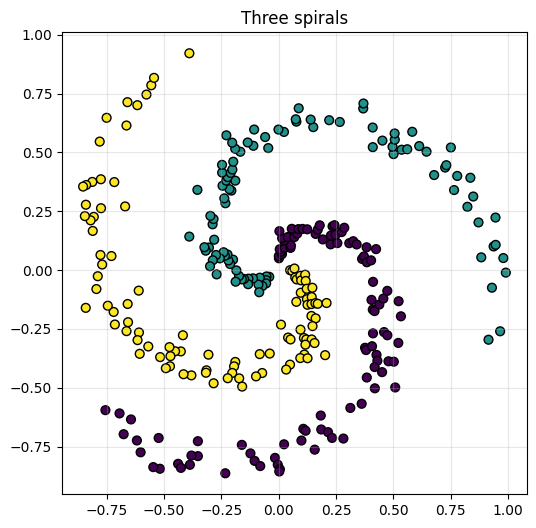

In [5]:
def make_spirals(n_per_class=100, n_classes=3, noise=0.2, seed=0):
    rng = np.random.default_rng(seed)
    X = np.zeros((n_per_class * n_classes, 2))
    y = np.zeros(n_per_class * n_classes, dtype=int)
    for c in range(n_classes):
        idx = slice(n_per_class * c, n_per_class * (c + 1))
        radius = np.linspace(0.05, 1, n_per_class)
        angle = np.linspace(4 * c, 4 * (c + 1), n_per_class) + rng.normal(0, noise, n_per_class)
        X[idx] = np.c_[radius * np.sin(angle), radius * np.cos(angle)]
        y[idx] = c
    return X, y

X_spiral, y_spiral = make_spirals()
Y_spiral = np.eye(3)[y_spiral]          # one-hot matrix Y (n x K)

plt.figure(figsize=(6, 6))
plt.scatter(X_spiral[:, 0], X_spiral[:, 1], c=y_spiral, cmap='viridis', edgecolor='k', s=40)
plt.title('Three spirals')
plt.grid(True, alpha=0.3)
plt.show()

In [6]:
def init_params(n_features, n_hidden, n_classes, seed=0):
    rng = np.random.default_rng(seed)
    return [
        rng.normal(0, 0.5, (n_features, n_hidden)),   # W_h
        np.zeros((1, n_hidden)),                      # b_h
        rng.normal(0, 0.5, (n_hidden, n_classes)),    # W_o
        np.zeros((1, n_classes)),                     # b_o
    ]

def tanh_prime(H):
    return 1 - np.tanh(H) ** 2

activations = {
    "relu": (relu, relu_prime, torch.relu),
    "tanh": (np.tanh, tanh_prime, torch.tanh),
}

params_spiral = init_params(n_features=2, n_hidden=16, n_classes=3)
labels_tensor = torch.tensor(y_spiral)
X_double = torch.tensor(X_spiral)               # float64 for an accurate comparison

for name, (act, act_prime, torch_act) in activations.items():
    grads_numpy = gradients(X_spiral, Y_spiral, params_spiral, act, act_prime)

    # (1) PyTorch autograd with the same parameters
    params_torch = [torch.tensor(p, requires_grad=True) for p in params_spiral]
    W_h_t, b_h_t, W_o_t, b_o_t = params_torch
    O_t = torch_act(X_double @ W_h_t + b_h_t) @ W_o_t + b_o_t
    loss_t = nn.functional.cross_entropy(O_t, labels_tensor)     # mean over observations
    loss_t.backward()
    match_autograd = all(np.allclose(g, p.grad.numpy()) for g, p in zip(grads_numpy, params_torch))

    # (2) Central finite differences for every entry of W_h
    eps = 1e-6
    W_h_grad_fd = np.zeros_like(params_spiral[0])
    for idx in np.ndindex(*params_spiral[0].shape):
        plus = [p.copy() for p in params_spiral];  plus[0][idx] += eps
        minus = [p.copy() for p in params_spiral]; minus[0][idx] -= eps
        W_h_grad_fd[idx] = (cross_entropy(Y_spiral, forward(X_spiral, plus, act)[2])
                            - cross_entropy(Y_spiral, forward(X_spiral, minus, act)[2])) / (2 * eps)
    match_fd = np.allclose(grads_numpy[0], W_h_grad_fd, atol=1e-6)

    print(f"{name}: matches autograd: {match_autograd}, matches finite differences (W_h): {match_fd}")
    assert match_autograd and match_fd

relu: matches autograd: True, matches finite differences (W_h): True


tanh: matches autograd: True, matches finite differences (W_h): True
